# 00 · PPMI Imaging — Study Overview & Cohort
> *Start here. No neuroscience background required.*

## What is Parkinson's Disease?

Parkinson's Disease (PD) is a progressive brain disorder that affects ~10 million people worldwide.

**Root cause:** Neurons that produce **dopamine** — a chemical messenger that coordinates smooth movement — gradually die off in a brain region called the **Substantia Nigra**.

By the time the first tremor or stiffness appears, **60–80% of dopamine neurons are already gone**. This makes early detection and biomarker research critical.

**Non-motor symptoms often appear years before movement problems:** loss of smell (anosmia), REM sleep disorder, constipation, depression.

---

## What is PPMI?

The **Parkinson's Progression Markers Initiative (PPMI)** is one of the most comprehensive PD studies ever conducted. Launched in 2010, it tracks thousands of participants across international sites with detailed clinical and biological measurements over many years.

**Goal:** Find reliable, objective markers that can detect PD early and track its progression.

**Three participant groups:**

| Cohort | Description |
|--------|-------------|
| **PD** | Confirmed Parkinson's diagnosis (recently diagnosed, < 2 years) |
| **Prodromal** | Pre-diagnostic: show early warning signs (REM sleep disorder, smell loss) but no PD yet |
| **Healthy Control (HC)** | Age-matched healthy volunteers for comparison |

---

## What is "Imaging Data"?

This dataset contains **processed measurements** extracted from brain scans — not the raw images themselves. Think of it as: MRI machine → computer analysis → numbers in a spreadsheet.

Each row in a file typically represents one scan session for one participant at one visit.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## File Inventory
Let's count what we have across all imaging files.

In [3]:
files = {
    'DaTSCAN Scan Log': 'Dopamine_Imaging_12Nov2026.csv',
    'DaTSCAN Quant SBR': 'Xing_Core_Lab_-_Quant_SBR_12Nov2026.csv',
    'DaTSCAN Visual Read': 'Xing_Core_Lab_-_Visual_Read_12Nov2026.csv',
    'MRI Core Log': 'Magnetic_Resonance_Imaging__MRI__12Nov2026.csv',
    'MRIQC (MRI Quality)': 'MRIQC_12Nov2026.csv',
    'Grey Matter Volume': 'Grey_Matter_Volume_12Nov2026.csv',
    'FreeSurfer Thickness': 'FS7_APARC_CTH_12Nov2026.csv',
    'FreeSurfer SA': 'FS7_APARC_SA_12Nov2026.csv',
    'FreeSurfer Vol': 'FS7_ASEG_VOL_12Nov2026.csv',
    'DTI Regions': 'DTI_Regions_of_Interest_12Nov2026.csv',
    'PET AV-133 Metadata': 'PET_Acquisition_Metadata_12Nov2026.csv',
    'PET AV-133 SBR': 'PET_SBR_Analysis_12Nov2026.csv',
    'TAU PET Analysis': 'TAU_PET_Analysis_12Nov2026.csv',
    'SV2A PET SUVR': 'SV2A_PET_SUVR_Analysis_12Nov2026.csv',
    'Safety CT': 'Safety_Head_CT_Scan_12Nov2026.csv',
}
rows = []
for label, fname in files.items():
    p = DATA_DIR / fname
    if p.exists():
        df = pd.read_csv(p)
        rows.append({'File': label, 'Rows': f'{len(df):,}',
                     'Participants': df['PATNO'].nunique() if 'PATNO' in df.columns else '—',
                     'Visits': df['EVENT_ID'].nunique() if 'EVENT_ID' in df.columns else '—'})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

                File   Rows  Participants Visits
    DaTSCAN Scan Log 16,069          7745     29
   DaTSCAN Quant SBR 10,808          4899     24
 DaTSCAN Visual Read  2,334          2325      —
        MRI Core Log 13,658          6649     20
 MRIQC (MRI Quality)  1,740          1740      1
  Grey Matter Volume    363           137      3
FreeSurfer Thickness  1,716          1716      1
       FreeSurfer SA  1,716          1716      1
      FreeSurfer Vol  1,713          1713      1
         DTI Regions  1,200           263      —
 PET AV-133 Metadata    257           126     12
      PET AV-133 SBR    256           125     12
    TAU PET Analysis     23            23     13
       SV2A PET SUVR  1,584            15      2
           Safety CT    958           958      1


## Participant Count per Modality

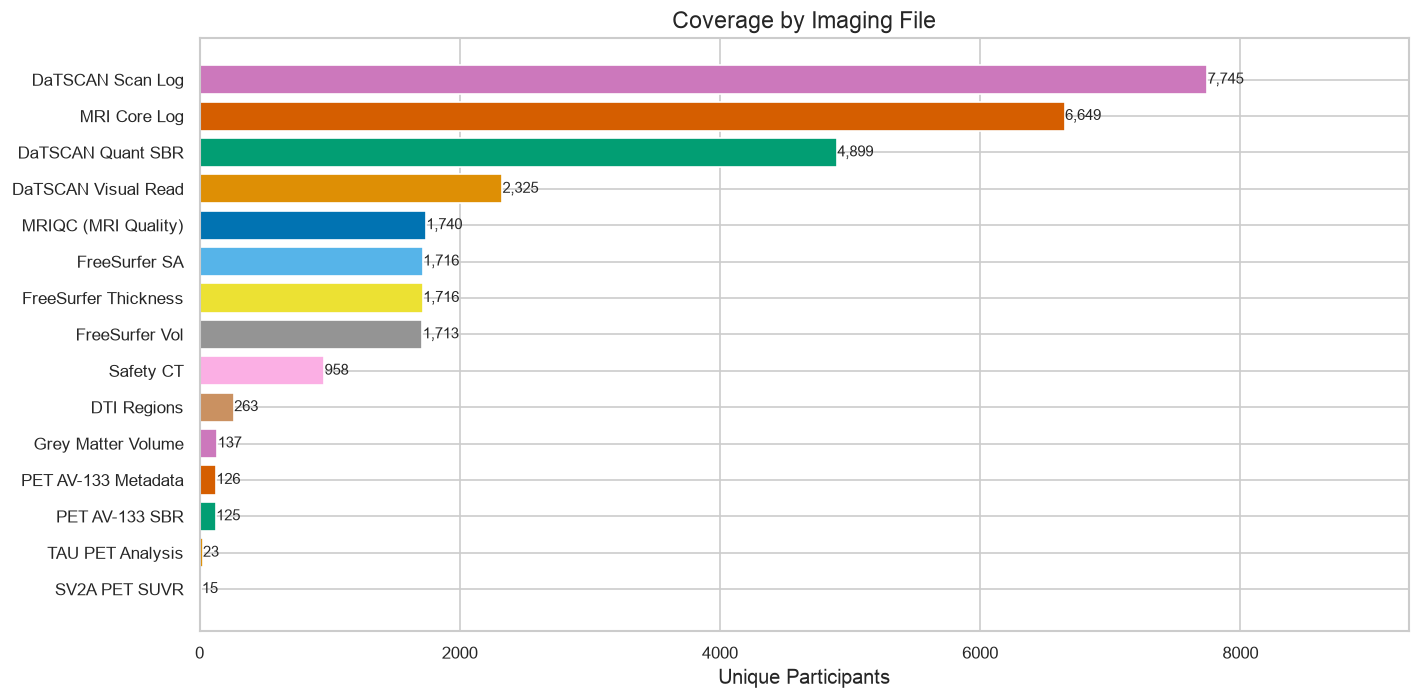

In [4]:
numeric = [(r['File'], r['Participants']) for _, r in summary.iterrows()
           if isinstance(r['Participants'], (int, np.integer))]
numeric.sort(key=lambda x: x[1])
labels, counts = zip(*numeric)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(labels, counts, color=sns.color_palette('colorblind', len(labels)))
ax.set_xlabel('Unique Participants')
ax.set_title('Coverage by Imaging File')
for b, v in zip(bars, counts):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height()/2, f'{v:,}', va='center', fontsize=9)
ax.set_xlim(0, max(counts) * 1.2)
plt.tight_layout(); plt.show()

## Visit Schedule

| Code | Meaning |
|------|--------|
| SC | Screening — first contact |
| BL | Baseline — start of study |
| V04–V16 | Annual follow-up visits (every 2 years) |
| PW | Premature Withdrawal |
| U01, U02 | Unscheduled visits |

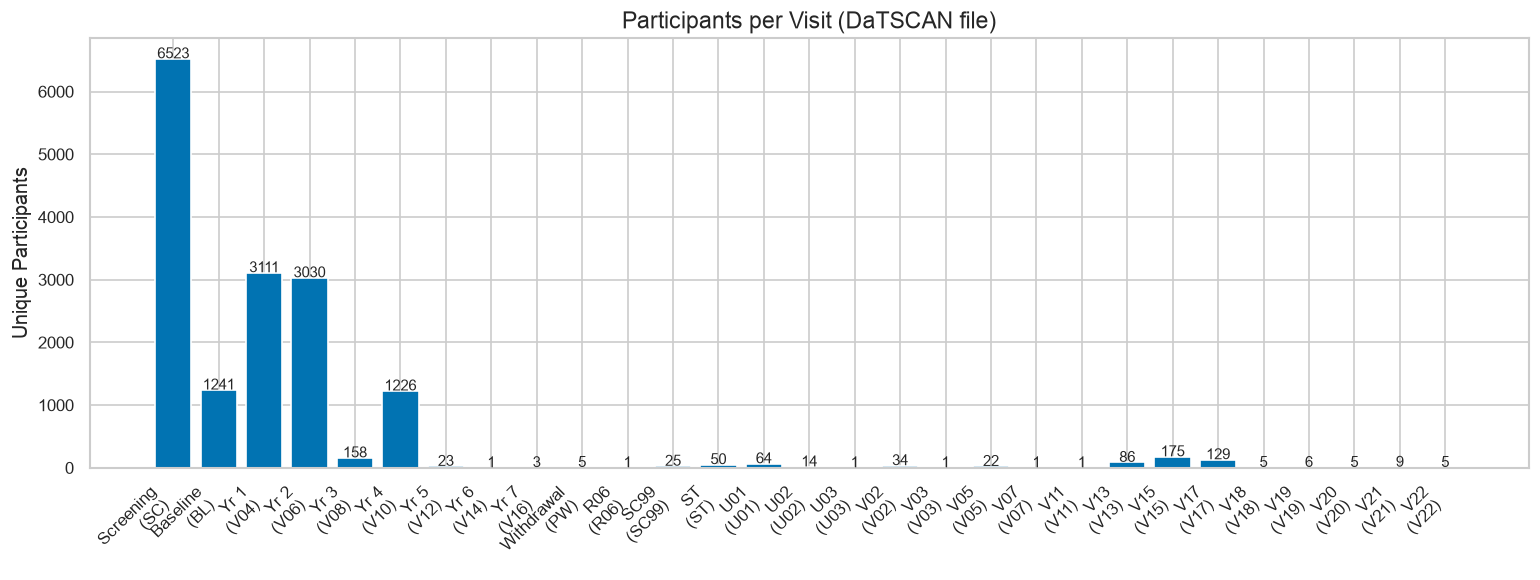

In [5]:
datscan = pd.read_csv(DATA_DIR / 'Dopamine_Imaging_12Nov2026.csv')
visits = ordered_visits(datscan['EVENT_ID'])
vc = datscan.groupby('EVENT_ID')['PATNO'].nunique().reindex(visits).dropna()

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(range(len(vc)), vc.values, color=sns.color_palette('colorblind')[0])
ax.set_xticks(range(len(vc)))
ax.set_xticklabels([f'{VISIT_LABELS.get(v,v)}\n({v})' for v in vc.index], rotation=45, ha='right')
ax.set_ylabel('Unique Participants'); ax.set_title('Participants per Visit (DaTSCAN file)')
for b, v in zip(bars, vc.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+8, str(int(v)), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

## Key Takeaways

- **DaTSCAN SPECT** is the flagship modality — largest N, longest follow-up
- **Structural MRI + FreeSurfer** provides anatomical measures (~700 participants processed)
- **DTI** targets the Substantia Nigra specifically — the PD-critical region
- **PET substudies** (Tau, SV2A, AV-133) are smaller, cutting-edge biomarker pilots
- All files share `PATNO` and `EVENT_ID` as merge keys
- Proceed to **01_DaTSCAN_SPECT_EDA** for the richest dataset